# The learned surrogate approach against the plant: what a test-set score does not tell

**Question:** The state of the art judges a learned surrogate of a comminution model by its error against that model; what does the same surrogate say about the ten real HP500 surveys, and does the autoencoder warn when it does not know?

- **Level:** 3, State of the art
- **Prerequisites:** notebook 02 of this topic and notebook 01 of topic 05-real-surveys
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- state what the learned-surrogate state of the art claims and how it is validated;
- apply that same approach, the product's own surrogate, to the ten surveys and compare it with the measurement;
- find the input range where the network stops being a model of the engine, and show what it returns outside it;
- say whether the product's autoencoder warns at that point, and what that implies for how the surrogate may be used.

## Setup

The same four libraries as the rest of the topic.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

The imports add the survey reader and the calibrated-lane operating point of topic 05, the anomaly scorer, and the sweep ranges of the training domain.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from dataclasses import replace

from pipeline.hp500.surveys import read_surveys
from pipeline.model import sweep
from pipeline.model.bundles import anomaly_graph, anomaly_score, applicability, engine_outputs, load_bundle, surrogate_graph, surrogate_predict
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.stages.evaluate import _r2_mape
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Data

The ten HP500 surveys, with the engine's calibrated results at them, and the two released models. The surrogate and the autoencoder are released ChancaDEM models, trained by the product's own pipeline on a Latin-hypercube sweep of the engine and committed with their contracts (`surrogate-model`, `anomaly-model`). Licence class: MIT, as the rest of the repository; the training data is synthetic, drawn from the engine. The survey rows are from Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919, licence class CC BY 4.0. Files read: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` and the models under `data/derived/models/`.

The cell reads the surveys and the committed backbone, and fixes the models folder, then loads the two contracts, which carry the training ranges.

In [2]:
# Read the surveys and the committed backbone, and fix the models folder
surveys = read_surveys().accepted
backbone_doc = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))
models_dir = ROOT / "data" / "derived" / "models"
surrogate_bundle = load_bundle("surrogate-model", models_dir)
anomaly_bundle = load_bundle("anomaly-model", models_dir)
measured = np.array([s.feed_tph for s in surveys])
print("surveys:", len(surveys), "| measured throughput range [t/h]:", measured.min(), measured.max())

surveys: 10 | measured throughput range [t/h]: 813.0 1639.0


## Method

**What is run.** The product's surrogate is the learned-surrogate approach in the sense of the next section: a small network that emulates a phenomenological comminution model. The method of this notebook is the product's, the engine and its released network, run at the operating points of the ten surveys. The cell builds each survey's operating point on the calibrated lane, and then its synthetic-lane counterpart, the same inputs with the calibration off, which is the point the network can represent since it has no calibration input. From here to the end of the extrapolation the network and the autoencoder are read through their raw graphs (`surrogate_graph`, `anomaly_graph`), which skip the applicability rule on purpose, because what they return outside their domain is the evidence; the rule comes at the end. It prints the ore competence A*b of the calibrated lane next to the range the network was trained on.

In [3]:
# Build the calibrated operating point of each survey and compare its inputs with the training domain
calibrated = [operating_from_survey(s.css_mm, s.f80_mm) for s in surveys]
domain = sweep.RANGES["cone-sec"]
print("ore A*b of the calibrated lane:", calibrated[0].ore_axb, "| training range:", domain["ore_axb"])
outside = {s.survey: [k for k in domain if not domain[k][0] <= getattr(o, k) <= domain[k][1]] for s, o in zip(surveys, calibrated)}
print("inputs outside the training range, per survey:")
for survey, names in outside.items():
    print(f"  {survey:2d}: {names}")
alarms = [anomaly_graph(evaluate(o), anomaly_bundle, models_dir)["is_anomaly"] for o in calibrated]
print("autoencoder alarms on the calibrated results of the ten surveys:", sum(alarms), "of 10")

ore A*b of the calibrated lane: 677.3 | training range: (30, 110)
inputs outside the training range, per survey:
   1: ['ore_axb']
   2: ['ore_axb']
   3: ['feed_x63_mm', 'ore_axb']
   4: ['ore_axb']
   5: ['feed_x63_mm', 'ore_axb']
   6: ['ore_axb']
   7: ['ore_axb']
   8: ['ore_axb']
   9: ['ore_axb']
  10: ['ore_axb']
autoencoder alarms on the calibrated results of the ten surveys: 8 of 10


## State of the art

**The protocol, run.** The test-set score of that literature is run here on the product's network with a small independent draw, 60 points per machine with the evaluation's seed, so that the notebook shows what the score is before asking what it misses. The cell scores P80 and the throughput of the released surrogate against the engine on the points the engine accepts.

In [4]:
# Run the test-set protocol: R2 and MAPE of P80 and throughput on a small independent draw
test_points = sweep.label(sweep.draw(60, 67890))
answers = [surrogate_predict(r.op, models_dir)[0] for r in test_points]
for key, field in (("p80_mm", "p80"), ("throughput_tph", "throughput_tph")):
    truth_values = np.array([getattr(r, field) for r in test_points])
    network_values = np.array([a[key] for a in answers])
    r2, error = _r2_mape(network_values, truth_values)
    print(f"{key:15s} test points {len(test_points)}  R2 {r2:.4f}  MAPE {error:.2f} %")

p80_mm          test points 276  R2 0.9971  MAPE 4.22 %
throughput_tph  test points 276  R2 0.9984  MAPE 5.05 %


**The source.** Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) train a deep neural network to approximate the phenomenological models of a comminution circuit, in order to run circuit simulations faster. The product's framework card for this topic records the same reading of that work: a surrogate of a model and not of plant data, validated against the model it emulates, offline, reporting neither a held-out industrial comparison nor an uncertainty; the card also records a speed-up of about three thousand and error figures well under one percent, which are that paper's figures and not reproduced here, since neither its circuit nor its code is in this repository. What can be run is the approach, on the product's own engine.

Its protocol is a test-set score: a held-out draw from the same distribution as the training data, compared with the teacher. Notebook 02 ran it: R squared between 0.979 and 0.998. The question here is the one that protocol cannot ask: what does the surrogate say about a plant? The cell runs it at the ten surveys in two ways. The first is the honest one the network can do: the operating point with the calibration off and the ore at the edge of its training range, A*b = 100, which is what a user who stays inside the domain would have. The second is the point as the calibrated lane has it, with A*b = 677, far outside the range. For each it prints the mean absolute error of the throughput against the measurement, with the teacher's, the synthetic engine, and the calibrated backbone's for reference.

In [5]:
# Mean absolute throughput error against the measurement: the network inside and outside its domain, its teacher and the calibrated backbone
inside = [replace(o, calibrated=False, ore_axb=100.0, ore_wi=sweep.wi_of_axb(100.0)) for o in calibrated]
outside_domain = [replace(o, calibrated=False) for o in calibrated]
network_inside = np.array([surrogate_graph(o, surrogate_bundle, models_dir)["throughput_tph"] for o in inside])
network_outside = np.array([surrogate_graph(o, surrogate_bundle, models_dir)["throughput_tph"] for o in outside_domain])
teacher_inside = np.array([evaluate(o).throughput_tph for o in inside])
backbone_tph = np.array([s["backbone"]["throughput_tph"] for s in backbone_doc["surveys"]])


def mape(estimate):
    return float(np.mean(np.abs((estimate - measured) / measured)) * 100)


for name, values in (("surrogate, ore at the domain edge (A*b = 100)", network_inside), ("its teacher, the synthetic engine (A*b = 100)", teacher_inside), ("calibrated backbone (the engine's calibrated lane)", backbone_tph), ("surrogate at the calibrated lane's ore (A*b = 677)", network_outside)):
    print(f"{name:62s} MAPE {mape(values):7.2f} %")

surrogate, ore at the domain edge (A*b = 100)                  MAPE   24.78 %
its teacher, the synthetic engine (A*b = 100)                  MAPE   21.72 %
calibrated backbone (the engine's calibrated lane)             MAPE   11.55 %
surrogate at the calibrated lane's ore (A*b = 677)             MAPE  118.20 %


The figure draws the four estimates against the measured throughput, survey by survey, so that the gaps are visible one at a time.

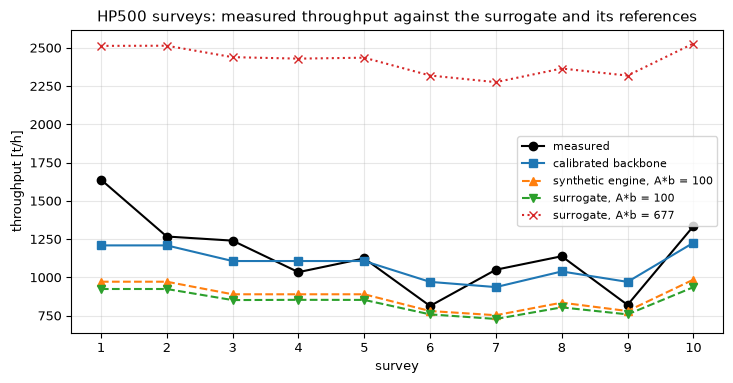

In [6]:
# Plot the measured throughput and the four estimates survey by survey
fig, ax = plt.subplots()
numbers = [s.survey for s in surveys]
ax.plot(numbers, measured, "ko-", label="measured")
ax.plot(numbers, backbone_tph, "s-", label="calibrated backbone")
ax.plot(numbers, teacher_inside, "^--", label="synthetic engine, A*b = 100")
ax.plot(numbers, network_inside, "v--", label="surrogate, A*b = 100")
ax.plot(numbers, network_outside, "x:", label="surrogate, A*b = 677")
ax.set_xticks(numbers)
ax.set_xlabel("survey")
ax.set_ylabel("throughput [t/h]")
ax.set_title("HP500 surveys: measured throughput against the surrogate and its references")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Four of the five lines run together at roughly the plant's level, within a few hundred t/h. The fifth does not: the surrogate at the calibrated lane's ore returns over 2300 t/h at every survey, more than twice the measurements. Of the in-domain lines, the surrogate and its teacher lie below the measurement and the calibrated backbone, which was fitted to the surveys, lies closest. The surrogate's error against the plant, 24.8 percent, is the teacher's 21.7 percent plus the network's own 3 points: the network passes on the teacher's error, whatever its R squared against it. The figure shows the gap to the plant is a property of the teacher, not of the learning.

**Where the network breaks.** The fifth line is not a calibration issue; it is an extrapolation. The training range of the ore competence is 30 to 110, and A*b = 677 is six times its upper edge. The engine copes with it, because the t10 relation saturates at its 0.44 cap, so it returns a finite, ordinary result; the network has no such cap. The cell sweeps the ore competence of S01 from inside the range to far outside it and prints, for the network and for the engine, the P80 and the power, together with the autoencoder's verdict on the engine's result at each point.

In [7]:
# Sweep the ore competence of S01 from inside the training range to far outside it
from pipeline.model.crusher import Operating

base = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
print("A*b   network P80  engine P80   network kW   engine kW   autoencoder alarm on the engine's result")
for axb in (30, 55, 110, 200, 400, 677):
    point = replace(base, ore_axb=float(axb), ore_wi=sweep.wi_of_axb(axb))
    answer = surrogate_graph(point, surrogate_bundle, models_dir)
    engine = evaluate(point)
    alarm = anomaly_graph(engine, anomaly_bundle, models_dir)["is_anomaly"]
    print(f"{axb:4d} {answer['p80_mm']:10.2f} {engine.p80:11.2f} {answer['power_kw']:12.1f} {engine.power_kw:11.1f}   {alarm}")

A*b   network P80  engine P80   network kW   engine kW   autoencoder alarm on the engine's result
  30      28.99       29.72        305.9       309.0   False
  55      27.50       27.70        275.6       284.3   False
 110      26.70       26.85        169.3       188.1   False
 200      21.00       26.85         -8.1       169.1   False
 400      11.96       26.85       -237.4       169.1   False
 677       5.75       26.85       -548.5       169.1   False


Inside the range the two agree. Past 110 the network's P80 keeps falling, from 26.7 mm to 5.75 mm, because it extrapolates the downward trend it learned, while the engine's stays at 26.85 mm; and its power goes through zero, to -8 kW at A*b = 200 and -548 kW at 677, a negative power that no machine has, while the engine's saturates at 169 kW. The last column is the finding: the autoencoder does not alarm at any of these points, because it scores the engine's result, and the engine's result at A*b = 677 is an ordinary one. The guard that the product describes as the surrogate's out-of-distribution check is blind to an input that is far outside the training range and that the engine saturates, which is exactly the case of the ten real surveys. The figure plots the power.

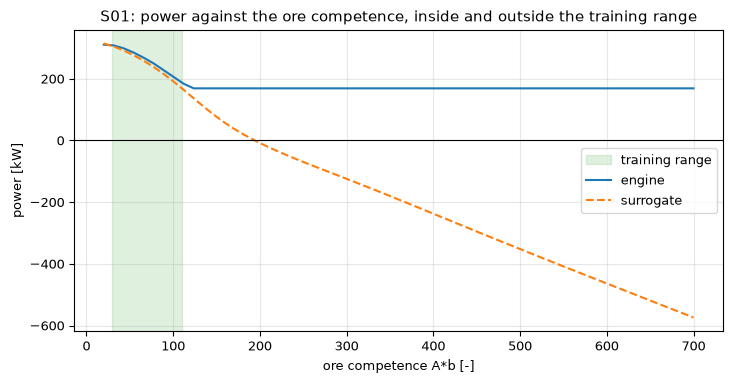

In [8]:
# Plot the power of the network and of the engine against the ore competence, with the training range shaded
grid = np.linspace(20, 700, 60)
points = [replace(base, ore_axb=float(a), ore_wi=sweep.wi_of_axb(a)) for a in grid]
fig, ax = plt.subplots()
ax.axvspan(*domain["ore_axb"], color="tab:green", alpha=0.15, label="training range")
ax.plot(grid, [evaluate(p).power_kw for p in points], label="engine")
ax.plot(grid, [surrogate_graph(p, surrogate_bundle, models_dir)["power_kw"] for p in points], "--", label="surrogate")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("ore competence A*b [-]")
ax.set_ylabel("power [kW]")
ax.set_title("S01: power against the ore competence, inside and outside the training range")
ax.legend()
fig.tight_layout()
plt.show()

The two curves agree in the green band and part company at its right edge: the network's line falls below zero while the engine's flattens. The figure shows the failure mode of a learned surrogate in one picture, an unconstrained extrapolation, and the guard of the engine's own envelope gate does not catch it either at A*b, which the gate does not test. What follows for use is simple: the network may answer inside the box of its training ranges and the product must check the box on the input, which a range test does exactly and for free, rather than rely on a detector of the output. The next cell is that test.

**The rule that refuses it.** The product does not leave that range test to the reader. Both model contracts record the training range of every continuous input for every machine (`training.input_ranges`, written by the training stage from the sweep's own ranges), and one applicability rule decides, in the pipeline and in the browser alike: a model applies to an operating point only when the point is not calibrated, because the models emulate the uncalibrated engine, and every continuous input lies inside its machine's range. Where it does not apply, the slot's baseline answers, labelled with the reason: the engine for the surrogate, the envelope gate for the autoencoder. The cell asks the slots, through the pipeline's wrappers, the questions the raw network answered above.

In [9]:
# Ask the slot, with the applicability rule, about the ten surveys and about the same points with the calibration off
from collections import Counter

verdicts = [applicability(o, surrogate_bundle) for o in calibrated]
print("surveys the rule refuses:", sum(not ok for ok, _ in verdicts), "of 10 | reasons:", dict(Counter(tuple(r) for _, r in verdicts)))
uncalibrated = [replace(o, calibrated=False) for o in calibrated]
print("the same points with the calibration off:", dict(Counter(tuple(applicability(o, surrogate_bundle)[1]) for o in uncalibrated)))
slot_answers = [surrogate_predict(o, models_dir) for o in calibrated]
print("provenance of the surrogate slot at the ten surveys:", dict(Counter(p for _, p in slot_answers)))
print("the slot's answer is the engine's own at every survey:", all(a == engine_outputs(evaluate(o)) for (a, _), o in zip(slot_answers, calibrated)))
print("power at survey 1 [kW], slot:", round(slot_answers[0][0]["power_kw"], 1), "| raw network:", round(surrogate_graph(calibrated[0], surrogate_bundle, models_dir)["power_kw"], 1))
anomaly_slot = [anomaly_score(evaluate(o), models_dir) for o in calibrated]
print("provenance of the autoencoder slot at the ten surveys:", dict(Counter(p for _, p in anomaly_slot)), "| keys of its answer:", sorted(anomaly_slot[0][0]))


surveys the rule refuses: 10 of 10 | reasons: {('calibrated_case',): 10}
the same points with the calibration off: {('outside_training_range:ore_axb',): 8, ('outside_training_range:feed_x63_mm', 'outside_training_range:ore_axb'): 2}
provenance of the surrogate slot at the ten surveys: {'baseline': 10}
the slot's answer is the engine's own at every survey: True
power at survey 1 [kW], slot: 408.3 | raw network: -572.8
provenance of the autoencoder slot at the ten surveys: {'baseline': 10} | keys of its answer: ['is_anomaly']


The rule refuses all ten surveys, each for one reason, `calibrated_case`: they run the calibrated fit and the models emulate the uncalibrated engine. With the calibration off the same points would still be refused, eight for the ore competence alone and two (surveys 3 and 5) also for the feed size, the list the earlier cell printed. The surrogate slot therefore answers every survey with the engine's own values and the provenance `baseline`: at survey 1 it gives 408.3 kW where the raw network gives -572.8 kW. The autoencoder slot does the same: its answer is the envelope gate's verdict alone, with no score. The raw readers stay in this notebook as the evidence of why the rule exists; the product's views and its bake never show their numbers at a point the rule refuses.

## Results

**Answer:** the surrogate approach is accurate against its teacher, and says about the plant what the teacher says: on a small independent draw of 276 points its test-set score is R squared 0.9971 for P80 and 0.9984 for the throughput. At the ten surveys, with the ore at the edge of the training range, the surrogate's mean absolute throughput error against the measurement is 24.78 percent, the synthetic engine's 21.72 and the calibrated backbone's 11.55: the network inherits the teacher's error and adds about 3 points. Fed the calibrated lane's ore, A*b = 677 against a training range of 30 to 110, it returns over 2300 t/h at every survey (118.20 percent mean error) and a power of about -575 kW. The autoencoder gives no alarm on the A*b sweep of S01, on none of 6 points, since the engine's result is ordinary there; on the calibrated results of the ten surveys it alarms on 8 of 10.

The first figure shows the gap to the plant is the teacher's, the second the failure past the range. A validator would conclude that a test-set R squared validates the emulation and nothing else, that the product's surrogate must be guarded on its input range and not only on an output detector, and that the real lane, calibrated and measured, is the evidence that the engine, not the network, brings to the plant. The product therefore applies the range test to the input: its two contracts record the training ranges, and one rule, the same in the pipeline and in the browser, refuses the surrogate and the autoencoder at all ten surveys, so the engine and the envelope gate answer there, labelled with the reason. These are the conclusions of a measurement on the product's own network; the paper's figures for its own circuit are not tested here.

## Summary

The learned-surrogate approach is validated against the model it emulates, and the product's network meets that bar; what it says about the plant is what its teacher says, less well. The network extrapolates without limit outside its training box, the autoencoder does not see it when the engine saturates, and a range test on the input would; the product now runs that test, from the ranges its contracts record, and answers with the engine or the envelope gate wherever the models do not apply. For the plant, the engine's calibrated lane and its held-out validation (topic 06) are the evidence, and the surrogate is a fast approximation to use inside its box.

## References

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919